# EEGNet 기반 운동상상 분류 (CSP + LDA와 비교)

`bci_analysis.ipynb`와 **같은 데이터·같은 전처리·같은 평가 방식**으로 EEGNet을 학습해 CSP + LDA와 비교합니다.

- 데이터: PhysioNet EEGBCI, Subject 1–10, Run 4·8·12 (왼손/오른손 운동상상), 1인당 45 trial
- 전처리: 8–30 Hz band-pass, 0–3초 구간 (CSP + LDA의 고정 설정과 동일)
- 평가 1: **피험자별 5-fold 교차검증** (CSP + LDA 고정 설정 CV와 같은 분할, `random_state=42`)
- 평가 2: **LOSO** — 9명으로 학습, 처음 보는 1명으로 평가
- 모델: EEGNet-8,2 (Lawhern et al., 2018), PyTorch 구현

### 설치 (처음 한 번)
RTX 4060에서 GPU로 학습하려면 CUDA 버전 PyTorch를 설치합니다.
```bash
pip install torch --index-url https://download.pytorch.org/whl/cu124
```

In [26]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from mne.datasets import eegbci
from scipy import stats
from sklearn.model_selection import StratifiedKFold, train_test_split

import torch
import torch.nn as nn

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
mne.set_log_level("WARNING")

DATA_PATH = Path(r"D:\bci_data")
RESULTS_DIR = Path("../results")
FIG_DIR = Path("../figures")
RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

SUBJECTS = list(range(1, 11))
MI_RUNS = [4, 8, 12]
FILTER_BAND = (8, 30)
TMIN, TMAX = 0.0, 3.0               # CSP + LDA 고정 설정과 동일
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

SEEDS = [0, 1, 2]                   # 신경망은 초기값에 따라 결과가 흔들려 3번 평균
WITHIN_EPOCHS = 200                 # 피험자별: 학습 36 trial뿐이라 검증셋 없이 고정 epoch
LOSO_MAX_EPOCHS = 300               # LOSO: 학습 피험자 안에서 검증셋을 떼어 early stopping
LOSO_PATIENCE = 30
BATCH_SIZE = 16
LR = 1e-3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"EEG 데이터 폴더가 없습니다: {DATA_PATH}")

PyTorch 2.6.0+cu124 | device: cuda | NVIDIA GeForce RTX 4060


## 1. 데이터 로드 (bci_analysis.ipynb와 동일한 함수)

In [27]:
def load_subject_epochs(subject, tmin=0.0, tmax=4.0):
    files = eegbci.load_data(subject, MI_RUNS, path=str(DATA_PATH), verbose=False)
    epochs_list = []
    for file in files:
        raw = mne.io.read_raw_edf(file, preload=True, verbose=False)
        events, event_id = mne.events_from_annotations(raw, verbose=False)
        epochs = mne.Epochs(
            raw, events,
            event_id={"left": event_id["T1"], "right": event_id["T2"]},
            tmin=tmin, tmax=tmax, baseline=None, preload=True, verbose=False,
        )
        epochs.filter(*FILTER_BAND, verbose=False)
        epochs_list.append(epochs)
    return mne.concatenate_epochs(epochs_list, verbose=False)


subject_data = {}
for s in SUBJECTS:
    ep = load_subject_epochs(s).crop(tmin=TMIN, tmax=TMAX)
    X = (ep.get_data() * 1e6).astype(np.float32)          # V → µV
    y = (ep.events[:, -1] == ep.event_id["right"]).astype(np.int64)  # left=0, right=1
    subject_data[s] = (X, y)

SFREQ = int(ep.info["sfreq"])
N_CH, N_T = X.shape[1], X.shape[2]
print(f"채널 {N_CH}, 샘플 {N_T} ({N_T / SFREQ:.2f}초, {SFREQ} Hz), 피험자당 trial {len(y)}")

C:\Users\kirig\AppData\Local\Temp\ipykernel_2080\3167574326.py:14: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(epochs_list, verbose=False)
C:\Users\kirig\AppData\Local\Temp\ipykernel_2080\3167574326.py:14: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(epochs_list, verbose=False)
C:\Users\kirig\AppData\Local\Temp\ipykernel_2080\3167574326.py:14: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(epochs_list, verbose=False)
C:\Users\kirig\AppData\Local\Temp\ipykernel_2080\3167574326.py:14: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(epochs_list, verbose=False)
C:\Users\kirig\AppData\Local\Temp\ip

채널 64, 샘플 481 (3.01초, 160 Hz), 피험자당 trial 45


C:\Users\kirig\AppData\Local\Temp\ipykernel_2080\3167574326.py:14: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(epochs_list, verbose=False)


## 2. EEGNet

원 논문은 128 Hz 기준 temporal kernel 64(=0.5초)를 씁니다. 이 데이터는 160 Hz라 같은 0.5초가 되도록 kernel을 80으로 맞췄습니다.

In [28]:
class EEGNet(nn.Module):
    def __init__(self, n_ch, n_t, n_classes=2, F1=8, D=2, F2=16, kern_len=80, dropout=0.5):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(1, F1, (1, kern_len), padding=(0, kern_len // 2), bias=False),
            nn.BatchNorm2d(F1),
            nn.Conv2d(F1, F1 * D, (n_ch, 1), groups=F1, bias=False),   # depthwise (공간 필터)
            nn.BatchNorm2d(F1 * D),
            nn.ELU(),
            nn.AvgPool2d((1, 4)),
            nn.Dropout(dropout),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(F1 * D, F1 * D, (1, 16), padding=(0, 8), groups=F1 * D, bias=False),  # separable
            nn.Conv2d(F1 * D, F2, 1, bias=False),
            nn.BatchNorm2d(F2),
            nn.ELU(),
            nn.AvgPool2d((1, 8)),
            nn.Dropout(dropout),
        )
        with torch.no_grad():
            n_feat = self.block2(self.block1(torch.zeros(1, 1, n_ch, n_t))).numel()
        self.classify = nn.Linear(n_feat, n_classes)

    def forward(self, x):
        x = self.block2(self.block1(x.unsqueeze(1)))
        return self.classify(x.flatten(1))


print(EEGNet(N_CH, N_T))
print("파라미터 수:", sum(p.numel() for p in EEGNet(N_CH, N_T).parameters()))

EEGNet(
  (block1): Sequential(
    (0): Conv2d(1, 8, kernel_size=(1, 80), stride=(1, 1), padding=(0, 40), bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): Conv2d(8, 16, kernel_size=(64, 1), stride=(1, 1), groups=8, bias=False)
    (3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): ELU(alpha=1.0)
    (5): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (6): Dropout(p=0.5, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=(0, 8), groups=16, bias=False)
    (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ELU(alpha=1.0)
    (4): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (5): Dropout(p=0.5, inplace=False)
  )
  (classify): Linear(in_features=240, out_features=2, bias=True)
)
파라미터 수: 2

## 3. 학습/평가 함수

- 채널별 표준화는 **학습 데이터의 평균·표준편차로만** 계산해 테스트에 적용합니다 (테스트 정보 누출 방지).
- 피험자별 CV는 학습셋이 36 trial뿐이라 검증셋을 떼지 않고 고정 epoch만 학습합니다. 테스트셋으로 epoch를 고르면 정확도가 부풀려지기 때문입니다.
- LOSO는 학습 피험자 9명 데이터 안에서만 10%를 검증셋으로 떼어 early stopping에 사용합니다. 테스트 피험자 데이터는 학습이 끝날 때까지 보지 않습니다.

In [29]:
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def standardize(X_train, *others):
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True) + 1e-6
    return [(X - mean) / std for X in (X_train, *others)]


def to_tensor(X, y=None):
    Xt = torch.from_numpy(X).to(DEVICE)
    return Xt if y is None else (Xt, torch.from_numpy(y).to(DEVICE))


@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    Xt, yt = to_tensor(X, y)
    return (model(Xt).argmax(1) == yt).float().mean().item()


def train_model(X_tr, y_tr, seed, epochs, X_val=None, y_val=None, patience=None):
    set_seed(seed)
    model = EEGNet(N_CH, N_T).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss()
    Xt, yt = to_tensor(X_tr, y_tr)
    best_val, best_state, wait, used_epochs = -1, None, 0, epochs
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(yt), device=DEVICE)
        for i in range(0, len(perm), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            opt.zero_grad()
            loss_fn(model(Xt[idx]), yt[idx]).backward()
            opt.step()
        if X_val is not None:
            val_acc = accuracy(model, X_val, y_val)
            if val_acc > best_val:
                best_val, wait = val_acc, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= patience:
                    used_epochs = epoch + 1
                    break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, used_epochs


def chance_threshold(n_trials, alpha=0.05):
    """2클래스에서 우연 수준을 넘는다고 볼 최소 정확도 (단측 이항검정)."""
    for k in range(n_trials + 1):
        if stats.binom.sf(k - 1, n_trials, 0.5) < alpha:
            return k / n_trials

## 4. 피험자별 5-fold 교차검증

In [30]:
t0 = time.time()
within_rows = []
for s in SUBJECTS:
    X, y = subject_data[s]
    seed_scores = []
    for seed in SEEDS:
        fold_scores = []
        for tr, te in CV.split(X, y):
            X_tr, X_te = standardize(X[tr], X[te])
            model, _ = train_model(X_tr, y[tr], seed, WITHIN_EPOCHS)
            fold_scores.append(accuracy(model, X_te, y[te]))
        seed_scores.append(np.mean(fold_scores))
    within_rows.append({"subject": s, "eegnet_within": np.mean(seed_scores),
                        "eegnet_within_seed_std": np.std(seed_scores)})
    print(f"Subject {s}: {np.mean(seed_scores) * 100:.1f}% (seed 간 ±{np.std(seed_scores) * 100:.1f})")
print(f"소요 {time.time() - t0:.0f}초")

Subject 1: 56.3% (seed 간 ±2.8)
Subject 2: 83.7% (seed 간 ±6.4)
Subject 3: 49.6% (seed 간 ±2.8)
Subject 4: 61.5% (seed 간 ±12.9)
Subject 5: 57.0% (seed 간 ±5.5)
Subject 6: 67.4% (seed 간 ±5.5)
Subject 7: 77.0% (seed 간 ±11.7)
Subject 8: 51.1% (seed 간 ±10.1)
Subject 9: 53.3% (seed 간 ±1.8)
Subject 10: 54.8% (seed 간 ±5.5)
소요 339초


## 5. LOSO (처음 보는 피험자에 대한 일반화)

In [31]:
t0 = time.time()
loso_rows = []
for test_s in SUBJECTS:
    X_tr_all = np.concatenate([subject_data[s][0] for s in SUBJECTS if s != test_s])
    y_tr_all = np.concatenate([subject_data[s][1] for s in SUBJECTS if s != test_s])
    X_te, y_te = subject_data[test_s]
    seed_scores, seed_epochs = [], []
    for seed in SEEDS:
        X_tr, X_val, y_tr, y_val = train_test_split(
            X_tr_all, y_tr_all, test_size=0.1, stratify=y_tr_all, random_state=seed)
        X_tr, X_val, X_te_n = standardize(X_tr, X_val, X_te)
        model, used = train_model(X_tr, y_tr, seed, LOSO_MAX_EPOCHS, X_val, y_val, LOSO_PATIENCE)
        seed_scores.append(accuracy(model, X_te_n, y_te))
        seed_epochs.append(used)
    loso_rows.append({"subject": test_s, "eegnet_loso": np.mean(seed_scores),
                      "eegnet_loso_seed_std": np.std(seed_scores),
                      "eegnet_loso_epochs": np.mean(seed_epochs)})
    print(f"Subject {test_s} 제외 후 테스트: {np.mean(seed_scores) * 100:.1f}% "
          f"(seed 간 ±{np.std(seed_scores) * 100:.1f}, 평균 {np.mean(seed_epochs):.0f} epoch)")
print(f"소요 {time.time() - t0:.0f}초")

Subject 1 제외 후 테스트: 48.9% (seed 간 ±6.5, 평균 54 epoch)
Subject 2 제외 후 테스트: 51.9% (seed 간 ±5.8, 평균 49 epoch)
Subject 3 제외 후 테스트: 52.6% (seed 간 ±1.0, 평균 55 epoch)
Subject 4 제외 후 테스트: 48.9% (seed 간 ±6.5, 평균 50 epoch)
Subject 5 제외 후 테스트: 45.9% (seed 간 ±9.3, 평균 56 epoch)
Subject 6 제외 후 테스트: 51.1% (seed 간 ±1.8, 평균 57 epoch)
Subject 7 제외 후 테스트: 45.9% (seed 간 ±10.9, 평균 63 epoch)
Subject 8 제외 후 테스트: 46.7% (seed 간 ±8.3, 평균 58 epoch)
Subject 9 제외 후 테스트: 51.9% (seed 간 ±4.2, 평균 76 epoch)
Subject 10 제외 후 테스트: 49.6% (seed 간 ±5.5, 평균 87 epoch)
소요 207초


## 6. CSP + LDA와 비교

CSP + LDA 값은 `bci_analysis.ipynb`의 **고정 설정(0–3초, CSP 4개) 5-fold CV**와 **LOSO** 결과입니다. 같은 시간 구간·같은 CV 분할이라 직접 비교할 수 있습니다.
(Nested CV 59.8%는 피험자별로 설정을 고른 결과라 이 비교에는 쓰지 않습니다.)

In [32]:
csp = pd.DataFrame({
    "subject": SUBJECTS,
    "csp_within": np.array([71.1, 55.6, 57.8, 51.1, 48.9, 46.7, 95.6, 48.9, 40.0, 53.3]) / 100,
    "csp_loso": np.array([64.4, 53.3, 44.4, 60.0, 48.9, 48.9, 55.6, 57.8, 46.7, 64.4]) / 100,
})
df = pd.DataFrame(within_rows).merge(pd.DataFrame(loso_rows), on="subject").merge(csp, on="subject")
df["chance_threshold"] = chance_threshold(len(subject_data[1][1]))
df.to_csv(RESULTS_DIR / "eegnet_results.csv", index=False, encoding="utf-8-sig")

show = df[["subject", "csp_within", "eegnet_within", "csp_loso", "eegnet_loso"]].copy()
show.columns = ["Subject", "CSP+LDA 개인 CV", "EEGNet 개인 CV", "CSP+LDA LOSO", "EEGNet LOSO"]
show.loc[len(show)] = ["평균"] + [show[c].mean() for c in show.columns[1:]]
display((show.set_index("Subject") * 100).round(1))
print(f"우연 수준 기준 (45 trial, p<0.05): {df['chance_threshold'].iloc[0] * 100:.1f}% 이상")

,CSP+LDA 개인 CV,EEGNet 개인 CV,CSP+LDA LOSO,EEGNet LOSO
Subject,,,,
1,71.1,56.3,64.4,48.9
2,55.6,83.7,53.3,51.9
3,57.8,49.6,44.4,52.6
4,51.1,61.5,60.0,48.9
5,48.9,57.0,48.9,45.9
6,46.7,67.4,48.9,51.1
7,95.6,77.0,55.6,45.9
8,48.9,51.1,57.8,46.7
9,40.0,53.3,46.7,51.9


우연 수준 기준 (45 trial, p<0.05): 64.4% 이상


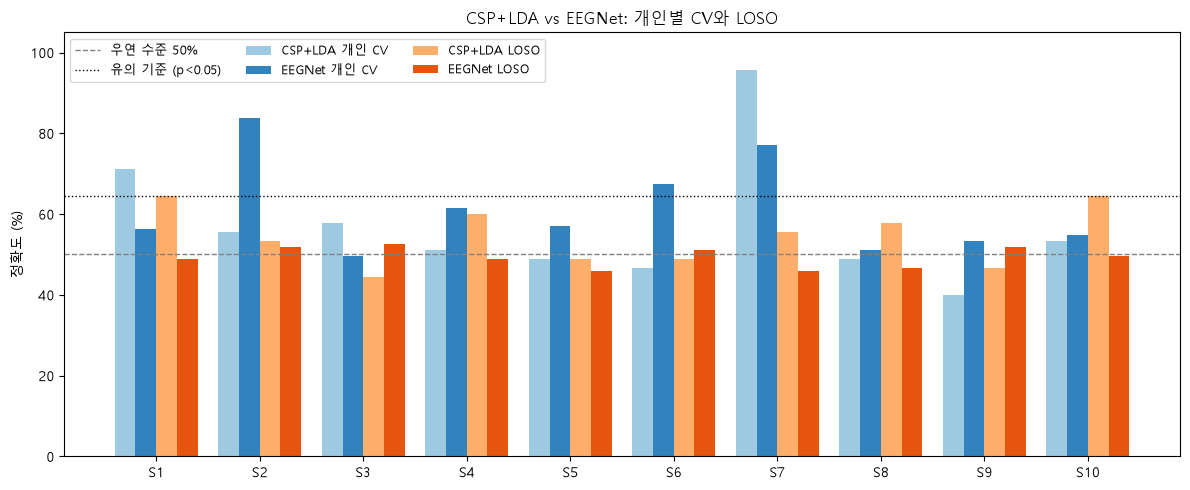

In [33]:
x = np.arange(len(SUBJECTS))
w = 0.2
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - 1.5 * w, df["csp_within"] * 100, w, label="CSP+LDA 개인 CV", color="#9ecae1")
ax.bar(x - 0.5 * w, df["eegnet_within"] * 100, w, label="EEGNet 개인 CV", color="#3182bd")
ax.bar(x + 0.5 * w, df["csp_loso"] * 100, w, label="CSP+LDA LOSO", color="#fdae6b")
ax.bar(x + 1.5 * w, df["eegnet_loso"] * 100, w, label="EEGNet LOSO", color="#e6550d")
ax.axhline(50, ls="--", c="gray", lw=1, label="우연 수준 50%")
ax.axhline(df["chance_threshold"].iloc[0] * 100, ls=":", c="black", lw=1, label="유의 기준 (p<0.05)")
ax.set_xticks(x, [f"S{s}" for s in SUBJECTS])
ax.set_ylabel("정확도 (%)")
ax.set_ylim(0, 105)
ax.set_title("CSP+LDA vs EEGNet: 개인별 CV와 LOSO")
ax.legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "eegnet_vs_csp.png", dpi=150)
plt.show()

## 7. 해석할 때 체크리스트

- [ ] EEGNet도 CSP + LDA처럼 **개인 CV보다 LOSO에서 성능이 떨어지는가?** → 피험자 간 차이가 모델 종류의 문제가 아니라는 근거가 됩니다.
- [ ] 개인 CV에서 EEGNet이 CSP + LDA보다 낮다면, 학습 trial이 36개뿐이라 신경망에 불리한 조건임을 함께 적습니다.
- [ ] LOSO는 학습 데이터가 405 trial로 늘어나므로 EEGNet이 상대적으로 유리할 수 있습니다.
- [ ] seed 간 편차(`*_seed_std`)가 피험자 간 차이보다 크지 않은지 확인합니다.
- [ ] 유의 기준선을 넘는 피험자가 몇 명인지 적습니다.